# Как устроен рой и как он меняется со временем

**H1.** У каплевидных роботов в параболическом потенциале ищем признаки образования и распада мицеллы. Сравним расстояния между соседями и движение агентов с глобальным параметром порядка $P_m$. Хиральные роботы на плоской поверхности образуют отдельную серию для будущей проверки.

**H2.** У овальных роботов сравним геометрию роёв разных размеров. От того, насколько сохраняется окружение отдельного робота, зависит выбор признаков для переноса графовой модели на новый размер роя.
Экспериментальная единица — повтор. При сравнении условий каждый опыт получает один голос независимо от числа роботов и кадров.

In [15]:
from pathlib import Path
from collections import Counter, defaultdict
import pickle
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.spatial.distance import pdist, squareform
from scipy.sparse.csgraph import connected_components
from IPython.display import display, Markdown
%matplotlib inline

raw = Path("data/raw")
manifest = pd.read_csv("data/download_manifest.csv")
missing = manifest.loc[manifest.status.eq("failed")].copy()
pilot = "N30_PWM10_abrasive_S"
sizes = [15, 30, 45]
controlled = [f"N{n}_PWM20_abrasive_S" for n in sizes]
figures = []
def finish(fig):
    fig.tight_layout()
    figures.append(fig)
    plt.show()
    plt.close(fig)

def geometry(xy, radius):
    distances = pdist(xy)
    matrix = squareform(distances)
    np.fill_diagonal(matrix, np.inf)
    nearest = np.partition(matrix, 2, axis=1)[:, :3]
    radial = np.linalg.norm(xy - xy.mean(axis=0), axis=1)
    rg = np.sqrt(np.mean(radial**2))
    edges = matrix <= radius
    _, labels = connected_components(edges, directed=False)
    return dict(NN=nearest.min(axis=1).mean(), K3=nearest.mean(), Rg=rg,
                Pair=distances.mean(), Density=len(xy)/(np.pi*rg**2),
                LCC=np.bincount(labels).max()/len(xy), Neighbours=edges.sum(axis=1).mean(),
                Radial=np.median(radial))

def initial_nn(xy):
    d = squareform(pdist(xy))
    np.fill_diagonal(d, np.inf)
    return np.median(d.min(axis=1))

def wrap(delta):
    return (delta + 180) % 360 - 180



## Данные и пропуски

В H1 координаты, угол и время записаны отдельными матрицами «робот × отсчёт». У части опытов сохранился только ряд параметра порядка.

In [16]:
config = pd.read_json("config/datasets.json", encoding="utf-8-sig")
runs, selected, extremes, errors = [], {}, [], []
for ds in config.itertuples():
    if not ds.dataset_group.startswith("h1"):
        continue
    condition = ds.condition
    records = defaultdict(dict)
    for path in sorted((raw/ds.dataset_group/condition).rglob("*")):
        if not path.is_file():
            continue
        key = re.search(r'(\d+_\d+_\[[^\]]+\])', path.name.lower()).group(1)
        kinds = {"data_x":"x","data_y":"y","data_ang":"angle","data_time":"time","data_t_p":"Pm"}
        kind = next((v for k,v in kinds.items() if path.name.lower().startswith(k)), None)
        kind = kind or {".csv":"Pm",".png":"image",".txt":"log"}[path.suffix]
        assert kind not in records[key]
        records[key][kind] = path
    for key, paths in records.items():
        row = dict(condition=condition, run=key, dataset="validation" if "validation" in ds.dataset_group else "main",
                   robot=condition.split("_")[3], N=int(condition.split("_")[0][1:]))
        arrays = {}
        for k,p in paths.items():
            if k=="log":
                errors.append(p.read_text(errors="replace").strip().splitlines()[-1])
            if p.suffix != ".csv":
                continue
            with p.open() as stream:
                header = stream.readline().startswith("time_s")
            arrays[k] = pd.read_csv(p,header=0 if header else None).to_numpy(float)
        channels = ["x","y","angle","time"]
        row.update({k:k in arrays for k in channels+["Pm"]})
        row["log"] = "log" in paths
        row["nan"] = sum(np.isnan(a).sum() for a in arrays.values())
        row["inf"] = sum(np.isinf(a).sum() for a in arrays.values())
        row["full"] = all(k in arrays for k in channels) and len({arrays[k].shape for k in channels if k in arrays})==1
        row["aligned"] = False
        if row["full"]:
            x,y,a,t = [arrays[k] for k in channels]
            row["shape"] = x.shape
            row["axes_ok"] = np.all(t==t[0]) and np.all(np.diff(t[0])>0) and len(x)==row["N"]
            row["aligned"] = "Pm" in arrays and np.array_equal(t[0],arrays["Pm"][:,0])
            step = np.hypot(np.diff(x),np.diff(y))
            row["held"] = np.mean(step==0)
            j,i = np.unravel_index(step.argmax(),step.shape)
            extremes.append(dict(dataset="H1",condition=condition,run=key,robot=j,frame=i+1,
                                 step=step[j,i],previous=step[j,i-1] if i else np.nan,
                                 following=step[j,i+1] if i+1<step.shape[1] else np.nan))
            if condition in [pilot,*controlled] and row["aligned"]:
                selected[condition,key] = (x,y,a,t[0],arrays["Pm"][:,1])
        row["usable"] = row["full"] and row["axes_ok"] and row["aligned"] and not(row["nan"] or row["inf"])
        runs.append(row)
h1 = pd.DataFrame(runs)
print("Пример матриц x, y, угол, время:", h1.loc[h1.full,"shape"].iloc[0])

Пример матриц x, y, угол, время: (15, 7576)


В Crystal formation один файл содержит последовательность кадров. Робота между кадрами сопоставляем по ID.

In [17]:
class TrackingReader(pickle.Unpickler):
    def find_class(self, module, name):
        return {("numpy","dtype"):np.dtype,
                ("numpy.core.multiarray","scalar"):np.core.multiarray.scalar}[module,name]

def load(path):
    with path.open("rb") as f:
        return TrackingReader(f).load()

crystal = sorted((raw/"h2_crystal_formation").rglob("*.pickle"))
print("Первые две детекции первого кадра:",load(crystal[0])[0][:2])
quality = []
for path in crystal:
    n,code,exp = map(int,re.search(r'(\d+)_bots_PWM_(\d+)_exp?_(\d+)',path.name,re.I).groups())
    frames = load(path)
    sets = [frozenset(o[0] for o in frame) for frame in frames]
    ids = frozenset.union(*sets)
    counts = np.array([len(frame) for frame in frames])
    values = np.array([(o[1],*o[2]) for frame in frames for o in frame])
    duplicates = sum(len(s)!=len(frame) for s,frame in zip(sets,frames))
    absent = sum(s!=ids for s in sets)
    quality.append(dict(path=path,series="sweep" if "sweep" in path.parent.name else "large_stats",
                        N=n,code=code,PWM=10*code,exp=exp,frames=len(frames),
                        exact=int(sum(counts==n)),below=int(sum(counts<n)),above=int(sum(counts>n)),
                        missing_id=absent,duplicates=duplicates,unique=len(ids),
                        nan=np.isnan(values).sum(),inf=np.isinf(values).sum(),
                        clean=bool(np.all(counts==n) and not duplicates and not absent and np.isfinite(values).all())))
h2=pd.DataFrame(quality)
sweep=h2.query("series=='sweep' and PWM==10").copy()
sweep["quality_pct"]=100*sweep.exact/sweep.frames

Первые две детекции первого кадра: [[2, 11.309932474020213, (1134, 420)], [4, 150.25511870305778, (798, 603)]]


In [18]:
display(h1.groupby(["dataset","robot"]).agg(повторов=("run","size"),траектории=("full","sum"),согласованы_с_Pm=("usable","sum"),логи=("log","sum")))
print("NaN и Inf в числовых измерениях:", int(h1[["nan","inf"]].sum().sum()+h2[["nan","inf"]].sum().sum()))

повторов  траектории  согласованы_с_Pm  логи
dataset    robot                                               
main       Oheavy        60           0                 0     9
           Olight        40          38                37     0
           S             60          58                58     0
validation Olight        20          19                18     0
           S             13          11                10     0

NaN и Inf в числовых измерениях: 0


В основной серии у S пригодны 58 из 60 повторов, у O-light — 37 из 40. У O-heavy во всех 60 повторах есть параметр порядка, но нет координат для анализа соседей. В хиральной серии доступны ещё 10 согласованных записей S и 18 O-light.

Для 17 файлов Яндекс Диск возвращал HTTP 500 при повторной автоматической и ручной загрузке. В пилоте H1 все пять повторов доступны. В серии H2 PWM10 у N45 сохранились четыре из пяти записей.

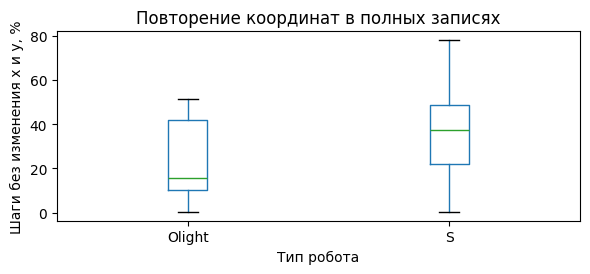

Медиана по 126 полным повторам: 28.75%


In [19]:
fig,ax=plt.subplots(figsize=(6,3))
h1.loc[h1.full].assign(percent=lambda d:100*d.held).boxplot(column="percent",by="robot",ax=ax,grid=False)
fig.suptitle("");ax.set(title="Повторение координат в полных записях",xlabel="Тип робота",ylabel="Шаги без изменения x и y, %")
finish(fig)
print(f"Медиана по {h1.full.sum()} полным повторам: {100*h1.held.median():.2f}%")

В 126 полных траекториях H1 медианная доля шагов без изменения обеих координат — 28,75%. Причиной может быть как малая подвижность, так и удержание последней позиции трекером. Поэтому для сравнения движения берём более длинный интервал.

## H1 · Пять повторов при N30

В пилоте одинаковы тип робота S, абразивная поверхность и PWM10. По каталогу мицелла образовалась в двух из пяти опытов, но номера этих опытов неизвестны. Для каждого выбранного времени берём ближайший отсчёт к моменту на секунду раньше. NN означает среднее расстояние до ближайшего соседа, K3 — до трёх ближайших, Rg — среднеквадратичное расстояние до центроида.

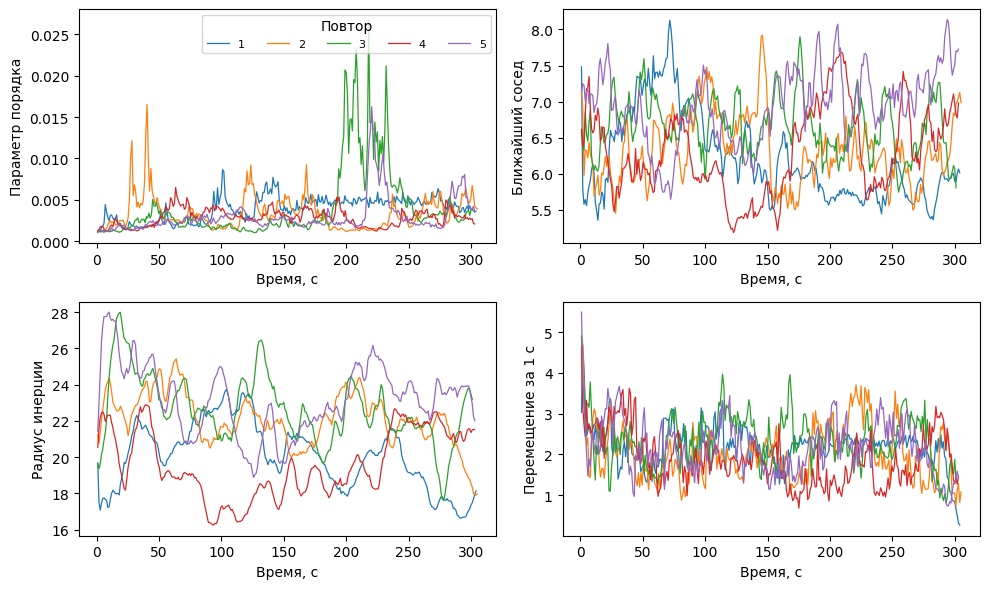

,Pm,NN,Rg,D1
rep,,,,
1,0.00420,6.01171,20.17767,2.24856
2,0.00292,6.25728,22.08267,1.96140
3,0.00248,6.65448,22.44156,2.34599
4,0.00281,6.19698,19.15685,1.80203
5,0.00233,6.95169,23.30824,2.14316


In [20]:
radius1=2*np.median([initial_nn(np.c_[x[:,0],y[:,0]]) for (cond,_),(x,y,*_) in selected.items() if cond==pilot])
rows=[]
for (cond,key),(x,y,a,t,p) in selected.items():
    # Равномерная выборка для геометрии; шаг всегда относится к предыдущему исходному кадру.
    for i in np.unique(np.linspace(np.searchsorted(t,t[0]+1),len(t)-1,301,dtype=int)):
        target=t[i]-1
        right=np.searchsorted(t,target)
        left=max(0,right-1)
        past=min((left,right),key=lambda j: abs(t[j]-target))
        xy=np.c_[x[:,i],y[:,i]]
        row=geometry(xy,radius1)
        rows.append(dict(condition=cond,run=key,N=len(x),time=t[i],Pm=p[i],
                         D1=np.median(np.hypot(x[:,i]-x[:,past],y[:,i]-y[:,past])),
                         Turn=np.median(abs(wrap(a[:,i]-a[:,i-1]))),**row))
profiles=pd.DataFrame(rows)
pilot_data=profiles.query("condition==@pilot")

pilot_data=pilot_data.copy()
pilot_data["rep"]=pilot_data.run.map({key:i for i,key in enumerate(sorted(pilot_data.run.unique()),1)})
fig,axs=plt.subplots(2,2,figsize=(10,6))
for rep,g in pilot_data.groupby("rep"):
    for ax,k,label in zip(axs.flat,["Pm","NN","Rg","D1"],["Параметр порядка","Ближайший сосед","Радиус инерции","Перемещение за 1 с"]):
        ax.plot(g.time,g[k],lw=.9,label=str(rep))
        ax.set(xlabel="Время, с",ylabel=label)
axs[0,0].legend(title="Повтор",ncol=5,fontsize=8)
finish(fig)
med=pilot_data.groupby("rep")[["Pm","NN","Rg","D1"]].median()
display(med.round(5))

В первом повторе медиана P_m самая высокая (0,00420), а ближайший сосед в среднем ближе всего (6,01). В пятом картина обратная: 0,00233 и 6,95. У перемещения за секунду другой порядок: самое большое значение в третьем повторе (2,35), самое малое в четвёртом (1,80).

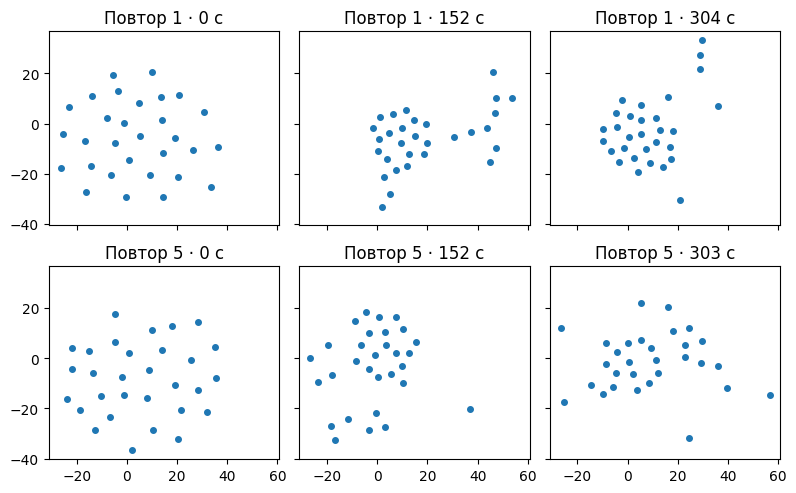

In [21]:
keys=sorted(key for cond,key in selected if cond==pilot)
fig,axes=plt.subplots(2,3,figsize=(8,5),sharex=True,sharey=True)
for row,rep in enumerate([1,5]):
    x,y,_,t,_=selected[pilot,keys[rep-1]]
    for ax,i in zip(axes[row],[0,len(t)//2,len(t)-1]):
        ax.scatter(x[:,i],y[:,i],s=16)
        ax.set_aspect("equal");ax.set_title(f"Повтор {rep} · {t[i]:.0f} с")
finish(fig)

В каждом снимке 30 роботов, масштабы осей общие. Показаны два повтора с крайними медианами NN в пилоте (6,01 и 6,95). Три кадра помогают увидеть пространственный смысл расстояния, но установить момент образования мицеллы по ним нельзя.

,NN,K3,Neighbours,D1,Turn,Rg
1,-0.44,-0.40,0.44,0.08,-0.18,-0.22
2,-0.26,-0.12,0.29,-0.45,-0.22,-0.25
3,-0.09,-0.21,0.34,-0.31,-0.14,-0.23
4,-0.03,-0.07,0.34,-0.34,-0.21,-0.37
5,0.00,-0.01,0.24,-0.23,-0.15,-0.17


,Медиана Pearson,Медиана Spearman
NN,-0.18,-0.09
K3,-0.08,-0.12
Neighbours,0.15,0.34
D1,-0.24,-0.31
Turn,-0.16,-0.18
Rg,-0.14,-0.23


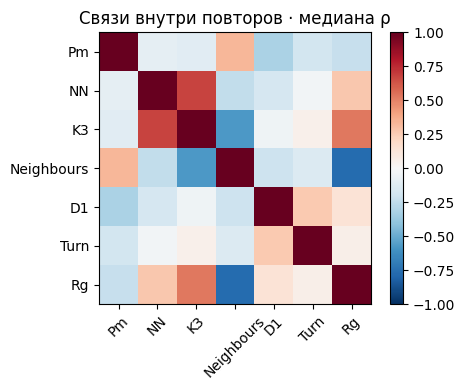

In [22]:
cols=["Pm","NN","K3","Neighbours","D1","Turn","Rg"]
groups=pilot_data.groupby("rep")
def correlations(method):
    return pd.DataFrame({rep:g[cols].corr(method=method)["Pm"] for rep,g in groups}).T.drop(columns="Pm")
rho=correlations("spearman")
display(rho.round(2))
display(pd.DataFrame({"Медиана Pearson":correlations("pearson").median(),"Медиана Spearman":rho.median()}).round(2))
matrix=pd.concat([g[cols].corr(method="spearman") for _,g in groups]).groupby(level=0).median().reindex(cols)
fig,ax=plt.subplots(figsize=(5,4))
im=ax.imshow(matrix,cmap="RdBu_r",vmin=-1,vmax=1)
ax.set(xticks=range(len(cols)),yticks=range(len(cols)),xticklabels=cols,yticklabels=cols,title="Связи внутри повторов · медиана ρ")
ax.tick_params(axis="x",rotation=45);fig.colorbar(im,ax=ax);finish(fig)

Число соседей положительно связано с P_m во всех пяти записях: ρ от 0,24 до 0,44 при выбранном радиусе. Для NN медиана всего −0,09, при этом в первом повторе ρ достигает −0,44. Для перемещения за секунду знак даже меняется: +0,08 в первом опыте и от −0,45 до −0,23 в остальных. Одновременные изменения признаков оставляют вопрос о раннем прогнозе открытым.

### Что меняется с размером роя?

При PWM20 сравним три размера на той же абразивной поверхности. Каталог сообщает о формировании в 4/5, 5/5 и 1/5 опытов соответственно. Каждая точка ниже — медиана одного опыта.

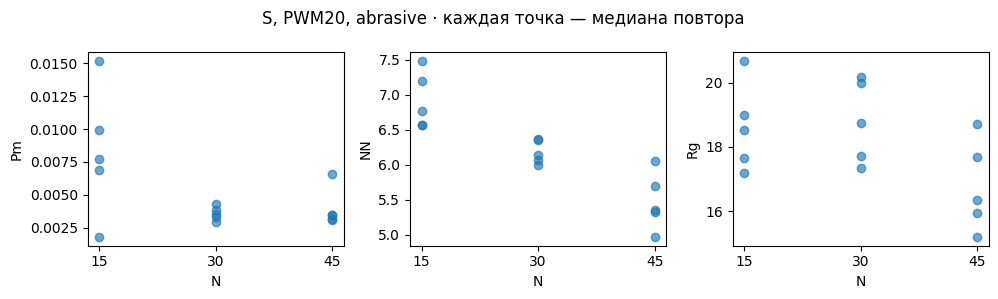

Pm                         NN                          Rg            \
     median      min      max   median      min      max    median       min   
N                                                                              
15  0.00773  0.00179  0.01519  6.76616  6.56062  7.48449  18.52479  17.19447   
30  0.00355  0.00296  0.00430  6.13267  5.99302  6.36657  18.74455  17.35046   
45  0.00345  0.00312  0.00656  5.35383  4.96674  6.05359  16.34216  15.20968   

              
         max  
N             
15  20.67391  
30  20.17033  
45  18.71673

In [23]:
size_summary=profiles.query("condition in @controlled").groupby(["N","run"])[["Pm","NN","Rg"]].median().reset_index()
fig,axs=plt.subplots(1,3,figsize=(10,3))
for ax,k in zip(axs,["Pm","NN","Rg"]):
    ax.scatter(size_summary.N,size_summary[k],alpha=.65);ax.set(xticks=sizes,xlabel="N",ylabel=k)
fig.suptitle("S, PWM20, abrasive · каждая точка — медиана повтора");finish(fig)

summary=size_summary.groupby("N")[["Pm","NN","Rg"]].agg(["median","min","max"])
display(summary.round(5))

С ростом N медианное NN уменьшается с 6,77 до 6,13 и 5,35. Rg при N15 и N30 близок (18,52 и 18,74), а при N45 ниже (16,34). Наибольший разброс P_m между опытами у N15: от 0,00179 до 0,01519. У N30 и N45 медианы P_m почти совпадают (0,00355 и 0,00345), хотя каталожные доли образования мицелл различаются.

## H2 · Перенос между размерами роя

Используем серию sweep с кодом PWM_1 (PWM10 по каталогу). Полным считаем трекинг с постоянным набором уникальных ID, номинальным числом роботов и конечными координатами и углами.

In [24]:
quality_table=sweep.groupby("N").agg(доступно=("exp","size"),полные=("clean","sum"),медиана_pct=("quality_pct","median"),минимум_pct=("quality_pct","min"))
lost=missing.loc[missing.condition.str.startswith("sweep")].remote_path.str.extract(r"(\d+)_bots_PWM_1_")[0].dropna().astype(int).value_counts()
quality_table.insert(0,"ожидалось",quality_table.доступно.add(lost,fill_value=0).astype(int))
display(quality_table.round(2))
display(h2.loc[~h2.clean,["series","N","PWM","exp","frames","exact","missing_id","duplicates"]])

,ожидалось,доступно,полные,медиана_pct,минимум_pct
N,,,,,
10,5,5,5,100.0,100.00
30,5,5,5,100.0,100.00
35,5,5,5,100.0,100.00
40,5,5,5,100.0,100.00
45,5,4,4,100.0,100.00
50,5,5,5,100.0,100.00
55,5,5,4,100.0,96.09
60,5,5,5,100.0,100.00
65,5,5,5,100.0,100.00


,series,N,PWM,exp,frames,exact,missing_id,duplicates
288,large_stats,45,20,61,641,641,1,1
300,sweep,55,10,1,921,885,35,1
307,sweep,35,20,3,931,922,8,1


При PWM10 полностью отслежены 43 из 44 записей. У N55 exp 1 число детекций совпало с номиналом в 885 из 921 кадров. Вне этой серии есть ещё два сбоя, включая опыт N45, где двойная детекция скрыла пропуск другого ID. Геометрию сравниваем по 43 полным записям.

In [25]:
def positions(frame):
    return np.asarray([o[2] for o in frame],float)
radius2=2*np.median([initial_nn(positions(load(p)[0])) for p in sweep.path])
scale_rows=[]
for r in sweep.itertuples():
    frames=load(r.path)
    sample=[]
    for i in np.unique(np.linspace(1,len(frames)-1,151,dtype=int)):
        frame=frames[i]
        prev={o[0]:o for o in frames[i-1]}
        if len(prev)!=len(frames[i-1]) or len({o[0] for o in frame})!=len(frame):
            continue
        geom=geometry(positions(frame),radius2)
        pairs=[(o,prev[o[0]]) for o in frame if o[0] in prev]
        geom["Step"]=np.median([np.linalg.norm(np.subtract(o[2],old[2])) for o,old in pairs])
        geom["Turn"]=np.median([abs(wrap(o[1]-old[1])) for o,old in pairs])
        sample.append(geom)
    scale_rows.append(dict(N=r.N,exp=r.exp,clean=r.clean,sampled=len(sample),**pd.DataFrame(sample).median().to_dict()))
scaling=pd.DataFrame(scale_rows)
clean=scaling.loc[scaling.clean]


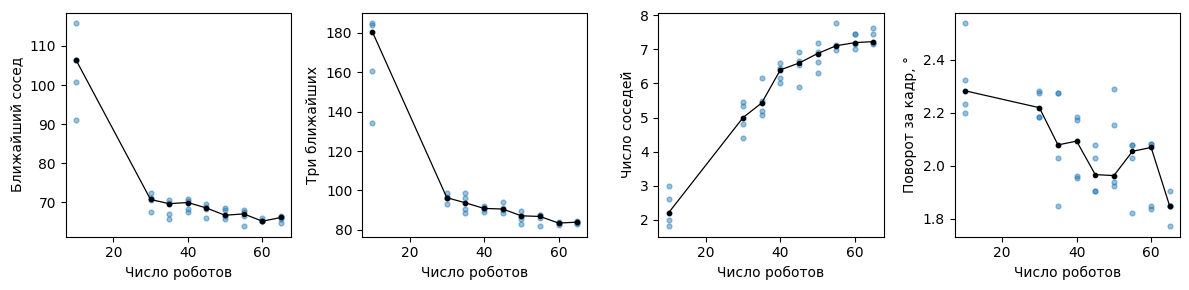

In [26]:
scales=["NN","K3","Neighbours","Turn","Step","Rg","Pair","Density"]
by_n=clean.groupby("N")[scales].median()
def scaling_plot(keys,labels):
    fig,axes=plt.subplots(1,len(keys),figsize=(3*len(keys),3))
    for ax,k,label in zip(axes,keys,labels):
        ax.scatter(clean.N,clean[k],s=12,alpha=.45)
        ax.plot(by_n.index,by_n[k],"k.-",lw=.9)
        ax.set(xlabel="Число роботов",ylabel=label)
    finish(fig)
scaling_plot(scales[:4],["Ближайший сосед","Три ближайших","Число соседей","Поворот за кадр, °"])

При N10 ближайший сосед находится в среднем дальше: медиана по повторам 106,4 против 65,2–70,8 при N30–65. Для K3 разница тоже заметна (180,6 при N10 и 83,9 при N65). Число соседей зависит от радиуса, общего для всей серии: он равен удвоенной медиане начального NN по повторам.

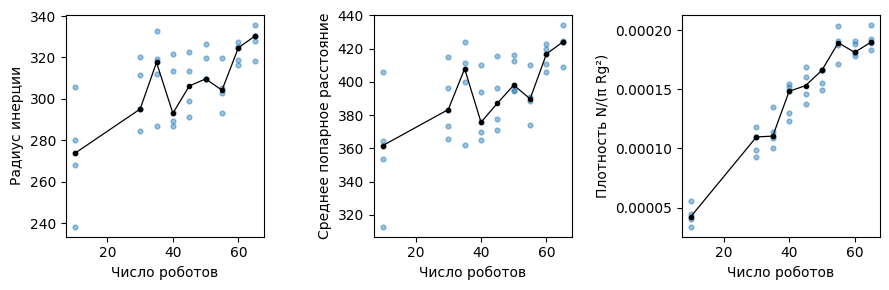

In [27]:
scaling_plot(scales[-3:],["Радиус инерции","Среднее попарное расстояние","Плотность N/(π Rg²)"])

От N10 к N65 радиус инерции увеличивается с 273,6 до 330,3, среднее попарное расстояние — с 361,6 до 424,1. Рост по промежуточным размерам немонотонен. При сходном расстоянии между соседями рои могут занимать разную площадь.

,Шаг,Частота,% ненулевых
0,1.000,438492,28.073
1,1.414,299364,19.166
2,2.236,239579,15.338
3,2.000,157084,10.057
4,3.162,82288,5.268
5,2.828,60109,3.848


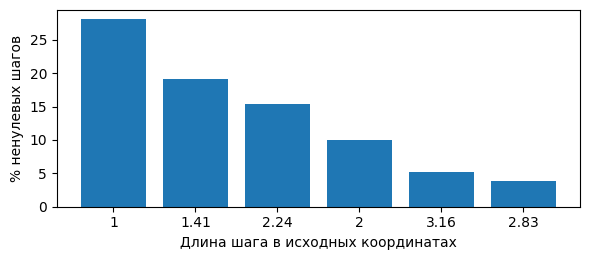

In [28]:
step_freq=Counter()
for r in sweep.itertuples():
    frames=load(r.path)
    # Матрица ID × кадр только для текущей записи; неоднозначные детекции остаются NaN.
    ids=sorted({o[0] for f in frames for o in f})
    index={v:j for j,v in enumerate(ids)}
    xy=np.full((len(ids),len(frames),2),np.nan)
    for i,frame in enumerate(frames):
        seen=Counter(o[0] for o in frame)
        for id_,_,point in frame:
            if seen[id_]==1: xy[index[id_],i]=point
    step=np.linalg.norm(np.diff(xy,axis=1),axis=2)
    positive=step[np.isfinite(step)&(step>0)]
    vals,counts=np.unique(np.round(positive,6),return_counts=True)
    step_freq.update(dict(zip(vals,counts)))
    j,i=np.unravel_index(np.nanargmax(step),step.shape)
    extremes.append(dict(dataset="H2",condition=f"N{r.N}_PWM10",run=r.exp,robot=ids[j],frame=i+1,
                         step=step[j,i],previous=step[j,i-1] if i else np.nan,
                         following=step[j,i+1] if i+1<step.shape[1] else np.nan))

peaks=pd.DataFrame(step_freq.most_common(6),columns=["Шаг","Частота"])
peaks["% ненулевых"]=100*peaks.Частота/sum(step_freq.values())
display(peaks.round(3))
fig,ax=plt.subplots(figsize=(6,2.7))
ax.bar(peaks.Шаг.map(lambda x:f"{x:.3g}"),peaks["% ненулевых"])
ax.set(xlabel="Длина шага в исходных координатах",ylabel="% ненулевых шагов")
finish(fig)

Из всех ненулевых перемещений 28,1% имеют длину 1, ещё 19,2% — √2. Следующие пики приходятся на √5 и 2. Эти длины соответствуют смещениям на целое число делений координатной сетки. Для перевода шага в физическую скорость нужны масштаб и интервал между кадрами.

## Крупные перемещения

In [29]:
outliers=pd.DataFrame(extremes).sort_values("step",ascending=False)
display(outliers.groupby("dataset").head(3).sort_values(["dataset","step"],ascending=[True,False]).round(2))

,dataset,condition,run,robot,frame,step,previous,following
99,H1,N46_PWM20_smooth_S_chiral,01_301_[n_46_bots_pwm_20_with_bolt_without_abr...,17,4772,110.72,0.20,0.16
120,H1,N46_PWM20_smooth_Olight_chiral,01_301_[n_46_bots_pwm_20_without_bolt_without_...,5,1253,110.56,110.34,110.39
109,H1,N46_PWM20_smooth_Olight_chiral,00_300_[n_46_bots_pwm_20_without_bolt_without_...,6,5351,110.26,0.47,0.47
128,H2,N65_PWM10,2,51,624,169.03,2.24,0.00
142,H2,N30_PWM10,3,75,7,38.63,18.03,0.00
154,H2,N65_PWM10,1,0,33,34.37,14.00,0.00


В таблице приведены максимумы разных повторов и шаги того же робота до и после. Резкое движение возможно при столкновении, ошибке трекинга или повторном захвате маркера. Причина отдельных скачков остаётся открытой.

## Выводы

**H1.** Из 95 пригодных основных записей 58 относятся к S. Пять повторов пилота позволяют сравнить локальную геометрию с параметром порядка, но связь меняется от опыта к опыту. Для проверки раннего прогноза нужны физический критерий устойчивости и метки времени образования и распада.

**H2.** При N ≥ 30 расстояния до ближайшего соседа занимают сравнительно узкий диапазон, а N10 выделяется более редким окружением. В будущем сравнении графовых моделей стоит отдельно проверить перенос на N10 и вклад глобальной плотности. Для интерпретации движения в физических единицах нужны масштаб координат и частота кадров.